In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Load data

In [2]:
PROJECT_ROOT = Path.cwd().parent.parent
data_path = PROJECT_ROOT/"data/hyperliquid/case_study_data/pre_holdout.parquet"
df = pd.read_parquet(data_path)

# Compute cross-sectional IC 

On each day we rank the coins by the feature and by the forward return, and take the correlation of the two ranks (Spearman). That number is the day's cross-sectional information coefficient (IC). A positive IC means coins with a higher feature value tended to have a higher forward return that day.

- Days with fewer than 10 coins are skipped. Early 2023 has only 4 to 14 coins a day, and a rank correlation over a handful of coins is mostly noise.
- We then test whether the mean daily IC is different from 0. The 3 and 7-day forward returns overlap from one day to the next, so consecutive daily ICs are correlated and a plain t-test would overstate the significance. We use a HAC (heteroskedasticity and autocorrelation consistent, also called Newey-West) t-stat, with as many lags as the label has days.
- The 95% confidence interval of the mean IC is the mean IC plus or minus the t critical value times the same HAC standard error, so it agrees with the p-value: it excludes 0 exactly when the p-value is below 0.05.

In [3]:
# the features and the labels (with the number of days each label looks ahead)
features = ["past_log_return_7", "past_log_return_14", "past_log_return_30"]
labels = {"fwd_log_return_1": 1, "fwd_log_return_3": 3, "fwd_log_return_7": 7}

# a day needs at least this many coins to get an IC
MIN_SYMBOLS = 10

In [4]:
def daily_ic(df, feature, label):
    # keep only the rows that have both the feature and the label
    d = df.dropna(subset=[feature, label])
    # count the coins we have on each day
    coins_per_day = d.groupby("open_time")["symbol"].size()
    # the days that have enough coins
    good_days = coins_per_day[coins_per_day >= MIN_SYMBOLS].index
    # keep only those days
    d = d[d["open_time"].isin(good_days)]
    # on each day, the Spearman rank correlation between the feature and the label across the coins
    return d.groupby("open_time").apply(lambda day: day[feature].corr(day[label], method="spearman"))

In [5]:
# the daily IC of every feature-label pair, one column per pair
ic_daily = pd.DataFrame({
    (feature, label): daily_ic(df, feature, label)
    for feature in features
    for label in labels
})

ic_daily.head()

past_log_return_7                                    \
                           fwd_log_return_1 fwd_log_return_3 fwd_log_return_7   
open_time                                                                       
2023-04-04 00:00:00+00:00         -0.454545         0.006061        -0.175758   
2023-04-05 00:00:00+00:00         -0.212121        -0.127273        -0.478788   
2023-04-06 00:00:00+00:00         -0.503030        -0.636364        -0.272727   
2023-04-07 00:00:00+00:00          0.018182        -0.090909        -0.018182   
2023-04-08 00:00:00+00:00         -0.369697        -0.563636        -0.515152   

                          past_log_return_14                   \
                            fwd_log_return_1 fwd_log_return_3   
open_time                                                       
2023-04-04 00:00:00+00:00          -0.321212         0.018182   
2023-04-05 00:00:00+00:00           0.054545         0.030303   
2023-04-06 00:00:00+00:00           0.006061        -0.042424   
2023-04-07 00:00:00+00:00          -0.090909         0.151515   
2023-04-08 00:00:00+00:00          -0.248485        -0.296970   

                                           past_log_return_30  \
                          fwd_log_return_7   fwd_log_return_1   
open_time                                                       
2023-04-04 00:00:00+00:00        -0.381818          -0.018182   
2023-04-05 00:00:00+00:00        -0.018182          -0.042424   
2023-04-06 00:00:00+00:00         0.018182           0.018182   
2023-04-07 00:00:00+00:00        -0.006061          -0.103030   
2023-04-08 00:00:00+00:00         0.212121           0.139394   

                                                             
                          fwd_log_return_3 fwd_log_return_7  
open_time                                                    
2023-04-04 00:00:00+00:00         0.127273         0.151515  
2023-04-05 00:00:00+00:00         0.066667         0.127273  
2023-04-06 00:00:00+00:00         0.090909         0.175758  
2023-04-07 00:00:00+00:00         0.345455         0.103030  
2023-04-08 00:00:00+00:00         0.442424        -0.006061

In [6]:
def hac_test(ic, n):
    # regress the daily IC on a constant: the constant is the mean IC
    # HAC makes the standard error robust to the overlap of the n-day labels (n lags)
    result = sm.OLS(ic.to_numpy(), np.ones(len(ic))).fit(cov_type="HAC", cov_kwds={"maxlags": n}, use_t=True)
    # the 95% confidence interval of the mean IC, built from the HAC standard error
    ci_low, ci_high = result.conf_int(alpha=0.05)[0]
    # the mean IC, its HAC standard error, its t-stat, its two-sided p-value and its confidence interval
    return result.params[0], result.bse[0], result.tvalues[0], result.pvalues[0], ci_low, ci_high

In [7]:
rows = []
for (feature, label), ic in ic_daily.items():
    # the daily ICs of this pair (days that were skipped are empty)
    ic = ic.dropna()
    # test the mean IC against 0, using as many lags as the label has days
    mean_ic, se, t_stat, p_value, ci_low, ci_high = hac_test(ic, labels[label])
    # one row of the summary
    rows.append({
        "feature": feature,
        "label": label,
        "days": len(ic),
        "mean_ic": mean_ic,
        "std_ic": ic.std(),
        "se_hac": se,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "t_stat_hac": t_stat,
        "p_value": p_value,
    })

# the summary table, one row per feature-label pair
ic_summary = pd.DataFrame(rows).set_index(["feature", "label"]).round(4)
ic_summary

days  mean_ic  std_ic  se_hac  ci_low  \
feature            label                                                     
past_log_return_7  fwd_log_return_1   744  -0.0274  0.2463  0.0088 -0.0447   
                   fwd_log_return_3   744  -0.0225  0.2558  0.0132 -0.0484   
                   fwd_log_return_7   744  -0.0174  0.2549  0.0183 -0.0533   
past_log_return_14 fwd_log_return_1   744  -0.0019  0.2572  0.0089 -0.0195   
                   fwd_log_return_3   744   0.0088  0.2512  0.0130 -0.0168   
                   fwd_log_return_7   744   0.0319  0.2641  0.0194 -0.0061   
past_log_return_30 fwd_log_return_1   744   0.0056  0.2618  0.0093 -0.0127   
                   fwd_log_return_3   744   0.0270  0.2435  0.0127  0.0020   
                   fwd_log_return_7   744   0.0517  0.2440  0.0177  0.0169   

                                     ci_high  t_stat_hac  p_value  
feature            label                                           
past_log_return_7  fwd_log_return_1  -0.0100     -3.1004   0.0020  
                   fwd_log_return_3   0.0034     -1.7037   0.0889  
                   fwd_log_return_7   0.0185     -0.9527   0.3410  
past_log_return_14 fwd_log_return_1   0.0156     -0.2179   0.8275  
                   fwd_log_return_3   0.0344      0.6716   0.5020  
                   fwd_log_return_7   0.0700      1.6487   0.0996  
past_log_return_30 fwd_log_return_1   0.0238      0.5984   0.5498  
                   fwd_log_return_3   0.0520      2.1215   0.0342  
                   fwd_log_return_7   0.0865      2.9158   0.0037

# Mean target per feature quintile

The IC is one number per pair. To see the shape of the relationship we also look at the mean target in each feature quintile.

- On each day we rank the coins by the feature and cut them into 5 equal buckets: quintile 1 holds the coins with the lowest feature values and quintile 5 the highest
- On each day we take the mean target of every bucket, then average those daily means over all days. Cutting per day matches the cross-sectional IC and removes market-wide moves
- Days with fewer than 10 coins are skipped, as for the IC, so every bucket has at least 2 coins

A steady rise or fall from quintile 1 to 5 goes with a positive or negative IC. A jump in only one end bucket means the effect sits in one tail.

In [8]:
# the number of buckets
N_QUANTILES = 5


def daily_quantile_means(df, feature, label):
    # keep only the rows that have both the feature and the label
    d = df.dropna(subset=[feature, label])
    # count the coins we have on each day
    coins_per_day = d.groupby("open_time")["symbol"].size()
    # the days that have enough coins
    good_days = coins_per_day[coins_per_day >= MIN_SYMBOLS].index
    # keep only those days (copy so we can add a column)
    d = d[d["open_time"].isin(good_days)].copy()
    # on each day, rank the coins by the feature (ties broken by order, so every bucket gets filled)
    rank = d.groupby("open_time")[feature].rank(method="first")
    # on each day, cut the ranks into equal buckets numbered 1 (lowest feature) to N_QUANTILES (highest)
    d["quantile"] = rank.groupby(d["open_time"]).transform(lambda r: pd.qcut(r, N_QUANTILES, labels=False)) + 1
    # the mean label of every bucket on every day: one row per day, one column per bucket
    return d.groupby(["open_time", "quantile"])[label].mean().unstack()

In [9]:
# the mean target of every quintile, averaged over days, in percent: one row per feature-label pair
quantile_means = pd.DataFrame({
    (feature, label): daily_quantile_means(df, feature, label).mean() * 100
    for feature in features
    for label in labels
}).T

quantile_means.round(3)

quantile                                 1      2      3      4      5
past_log_return_7  fwd_log_return_1 -0.138 -0.127 -0.093 -0.142 -0.009
                   fwd_log_return_3 -0.460 -0.228 -0.235 -0.399 -0.158
                   fwd_log_return_7 -1.099 -0.499 -0.565 -0.706 -0.783
past_log_return_14 fwd_log_return_1 -0.227 -0.154 -0.099 -0.076  0.064
                   fwd_log_return_3 -0.576 -0.508 -0.227 -0.167  0.013
                   fwd_log_return_7 -1.585 -0.905 -0.662 -0.247 -0.217
past_log_return_30 fwd_log_return_1 -0.296 -0.072 -0.102 -0.027  0.002
                   fwd_log_return_3 -0.785 -0.283 -0.211 -0.149 -0.031
                   fwd_log_return_7 -1.769 -0.494 -0.566 -0.612 -0.175

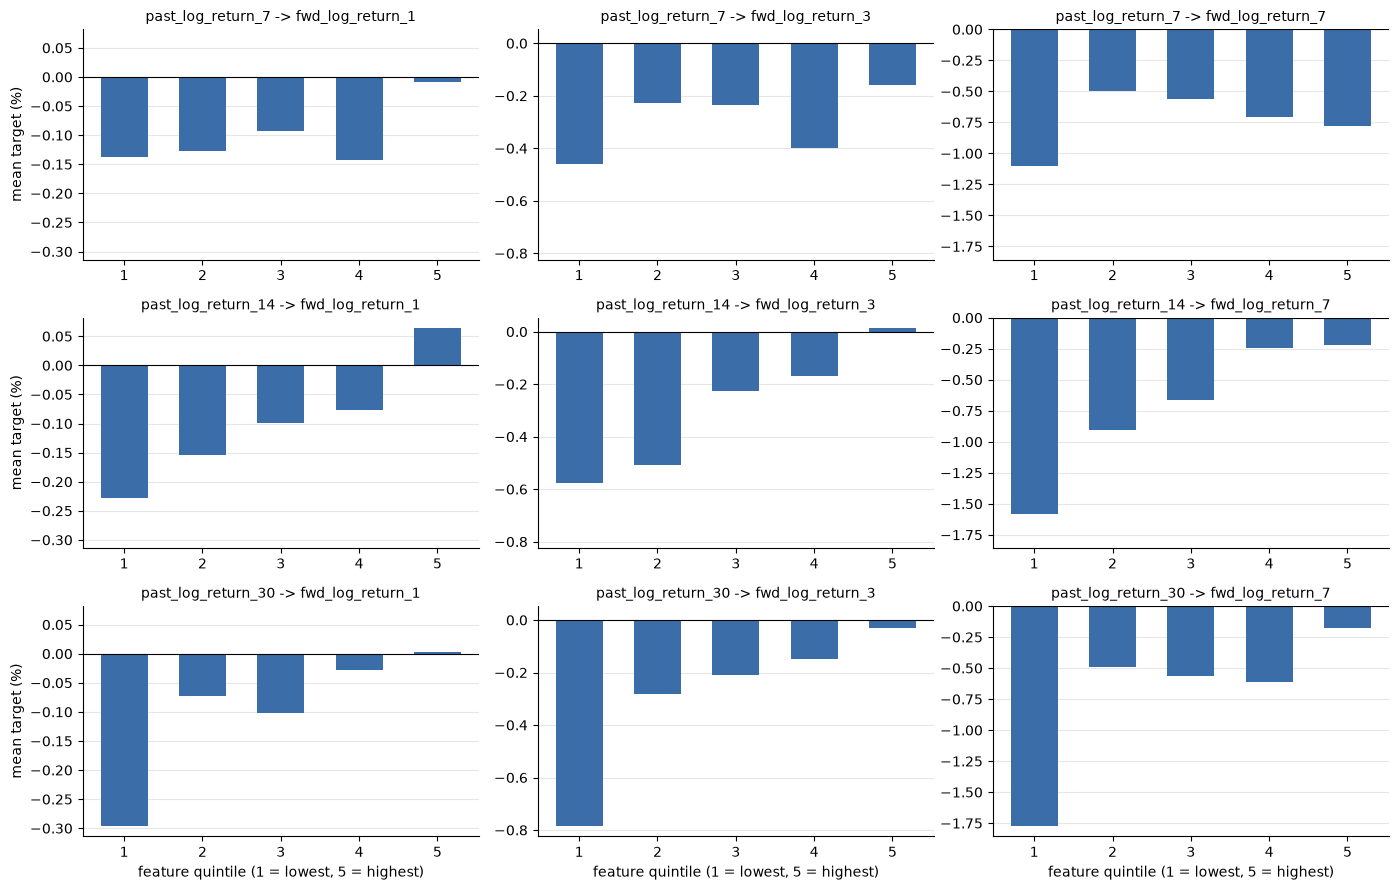

In [10]:
# one chart per feature (row) and label (column); the labels have different sizes, so each column has its own y-axis
fig, axes = plt.subplots(len(features), len(labels), figsize=(14, 9), sharey="col")

for i, feature in enumerate(features):
    for j, label in enumerate(labels):
        # the chart for this pair
        ax = axes[i, j]
        # one bar per quintile: the mean target in percent
        ax.bar(quantile_means.columns, quantile_means.loc[(feature, label)], width=0.6, color="#3b6ea8")
        # a line at 0 so up and down are easy to see
        ax.axhline(0, color="black", linewidth=0.8)
        # title: which feature and which label
        ax.set_title(f"{feature} -> {label}", fontsize=10)
        # the quintile numbers on the x-axis
        ax.set_xticks(list(quantile_means.columns))
        # light horizontal grid behind the bars, no box on the top and right
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        # axis names only on the outer charts
        if i == len(features) - 1:
            ax.set_xlabel("feature quintile (1 = lowest, 5 = highest)")
        if j == 0:
            ax.set_ylabel("mean target (%)")

plt.tight_layout()
plt.show()

# IC and quintiles by fold

A feature is only useful if its IC holds up over time, so we repeat the same calculations on separate periods of the pre-holdout data. Nothing is fitted for a raw feature, so the periods are used as plain time blocks, cut at the dates decided in `2_determining_cv_folds`:

- block 1: from the start to the fold 1 evaluation start (fold 1's train period)
- block 2: the fold 1 evaluation period
- block 3: the fold 2 evaluation period

The blocks do not overlap, so no day is counted twice (the fold 2 train set is block 1 plus block 2, so it is not a block of its own). Block 1 is thin: early 2023 has few coins a day, and days with fewer than 10 coins are skipped.

A row stays in a block only if its label ends before the block ends (`fwd_end_time_{n}`), so no label looks into the next block and the blocks stay independent. The holdout is not touched.

In [11]:
# the block boundaries, the same dates as in 2_determining_cv_folds
FOLD1_EVAL_START = pd.Timestamp("2024-03-25", tz="UTC")
FOLD2_EVAL_START = pd.Timestamp("2024-12-23", tz="UTC")
HOLDOUT_START = pd.Timestamp("2025-09-22", tz="UTC")

# the first day in the data
FIRST_DAY = df["open_time"].min()

# each block runs from its start (included) to its end (not included)
folds = {
    "block 1": (FIRST_DAY, FOLD1_EVAL_START),
    "block 2": (FOLD1_EVAL_START, FOLD2_EVAL_START),
    "block 3": (FOLD2_EVAL_START, HOLDOUT_START),
}

for name, (start, end) in folds.items():
    # the rows of this block, before the label purge
    block = df[(df["open_time"] >= start) & (df["open_time"] < end)]
    print(f"{name}: {start.date()} to {end.date()}, {block['open_time'].nunique()} days, {len(block)} rows")

block 1: 2023-03-28 to 2024-03-25, 363 days, 6531 rows
block 2: 2024-03-25 to 2024-12-23, 273 days, 13507 rows
block 3: 2024-12-23 to 2025-09-22, 266 days, 17687 rows


In [12]:
def fold_rows(df, start, end, n):
    # the rows that start inside the block
    in_block = (df["open_time"] >= start) & (df["open_time"] < end)
    # the rows whose n-day label is fully known before the block ends
    label_known = df[f"fwd_end_time_{n}"] < end
    # keep the rows that pass both
    return df[in_block & label_known]

In [13]:
rows = []
for fold, (start, end) in folds.items():
    for feature in features:
        for label, n in labels.items():
            # the rows of this block, purged for this label's horizon
            block = fold_rows(df, start, end, n)
            # the daily ICs of this pair inside the block
            ic = daily_ic(block, feature, label).dropna()
            # test the mean IC against 0, using as many lags as the label has days
            mean_ic, se, t_stat, p_value, ci_low, ci_high = hac_test(ic, n)
            # one row of the summary
            rows.append({
                "feature": feature,
                "label": label,
                "fold": fold,
                "days": len(ic),
                "mean_ic": mean_ic,
                "std_ic": ic.std(),
                "se_hac": se,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "t_stat_hac": t_stat,
                "p_value": p_value,
            })

# the summary table: the three blocks of a pair sit next to each other
fold_summary = pd.DataFrame(rows).set_index(["feature", "label", "fold"]).round(4)
fold_summary

days  mean_ic  std_ic  se_hac  \
feature            label            fold                                     
past_log_return_7  fwd_log_return_1 block 1   204  -0.0355  0.2894  0.0194   
                   fwd_log_return_3 block 1   202  -0.0311  0.3091  0.0309   
                   fwd_log_return_7 block 1   198  -0.0490  0.2996  0.0403   
past_log_return_14 fwd_log_return_1 block 1   204  -0.0151  0.3016  0.0191   
                   fwd_log_return_3 block 1   202   0.0002  0.2981  0.0304   
                   fwd_log_return_7 block 1   198   0.0221  0.3150  0.0429   
past_log_return_30 fwd_log_return_1 block 1   204  -0.0158  0.3034  0.0204   
                   fwd_log_return_3 block 1   202   0.0086  0.2756  0.0268   
                   fwd_log_return_7 block 1   198   0.0226  0.2521  0.0314   
past_log_return_7  fwd_log_return_1 block 2   272  -0.0270  0.2295  0.0135   
                   fwd_log_return_3 block 2   270  -0.0276  0.2388  0.0213   
                   fwd_log_return_7 block 2   266  -0.0390  0.2443  0.0308   
past_log_return_14 fwd_log_return_1 block 2   272  -0.0179  0.2362  0.0136   
                   fwd_log_return_3 block 2   270  -0.0201  0.2224  0.0194   
                   fwd_log_return_7 block 2   266  -0.0207  0.2362  0.0279   
past_log_return_30 fwd_log_return_1 block 2   272  -0.0009  0.2382  0.0140   
                   fwd_log_return_3 block 2   270   0.0080  0.2324  0.0210   
                   fwd_log_return_7 block 2   266   0.0277  0.2426  0.0300   
past_log_return_7  fwd_log_return_1 block 3   266  -0.0207  0.2278  0.0139   
                   fwd_log_return_3 block 3   266  -0.0075  0.2264  0.0183   
                   fwd_log_return_7 block 3   266   0.0289  0.2247  0.0255   
past_log_return_14 fwd_log_return_1 block 3   266   0.0258  0.2393  0.0142   
                   fwd_log_return_3 block 3   266   0.0469  0.2366  0.0193   
                   fwd_log_return_7 block 3   266   0.0925  0.2401  0.0299   
past_log_return_30 fwd_log_return_1 block 3   266   0.0287  0.2503  0.0148   
                   fwd_log_return_3 block 3   266   0.0594  0.2265  0.0191   
                   fwd_log_return_7 block 3   266   0.0928  0.2358  0.0295   

                                             ci_low  ci_high  t_stat_hac  \
feature            label            fold                                   
past_log_return_7  fwd_log_return_1 block 1 -0.0738   0.0027     -1.8311   
                   fwd_log_return_3 block 1 -0.0920   0.0298     -1.0077   
                   fwd_log_return_7 block 1 -0.1284   0.0304     -1.2161   
past_log_return_14 fwd_log_return_1 block 1 -0.0527   0.0226     -0.7897   
                   fwd_log_return_3 block 1 -0.0598   0.0601      0.0052   
                   fwd_log_return_7 block 1 -0.0626   0.1067      0.5138   
past_log_return_30 fwd_log_return_1 block 1 -0.0561   0.0245     -0.7717   
                   fwd_log_return_3 block 1 -0.0442   0.0614      0.3217   
                   fwd_log_return_7 block 1 -0.0394   0.0846      0.7201   
past_log_return_7  fwd_log_return_1 block 2 -0.0537  -0.0004     -1.9955   
                   fwd_log_return_3 block 2 -0.0697   0.0144     -1.2954   
                   fwd_log_return_7 block 2 -0.0996   0.0216     -1.2683   
past_log_return_14 fwd_log_return_1 block 2 -0.0447   0.0090     -1.3113   
                   fwd_log_return_3 block 2 -0.0583   0.0180     -1.0387   
                   fwd_log_return_7 block 2 -0.0755   0.0342     -0.7417   
past_log_return_30 fwd_log_return_1 block 2 -0.0283   0.0266     -0.0626   
                   fwd_log_return_3 block 2 -0.0334   0.0495      0.3827   
                   fwd_log_return_7 block 2 -0.0314   0.0868      0.9227   
past_log_return_7  fwd_log_return_1 block 3 -0.0481   0.0067     -1.4848   
                   fwd_log_return_3 block 3 -0.0435   0.0285     -0.4112   
                   fwd_log_return_7 block 3 -0.0214   0.0792      1.1311   
past_log_return_14 fwd_log_return_

### Mean IC by block

One bar per block, with the 95% confidence interval as the line on each bar. A bar whose interval crosses 0, or a bar that flips sign between blocks, means the IC is not stable.

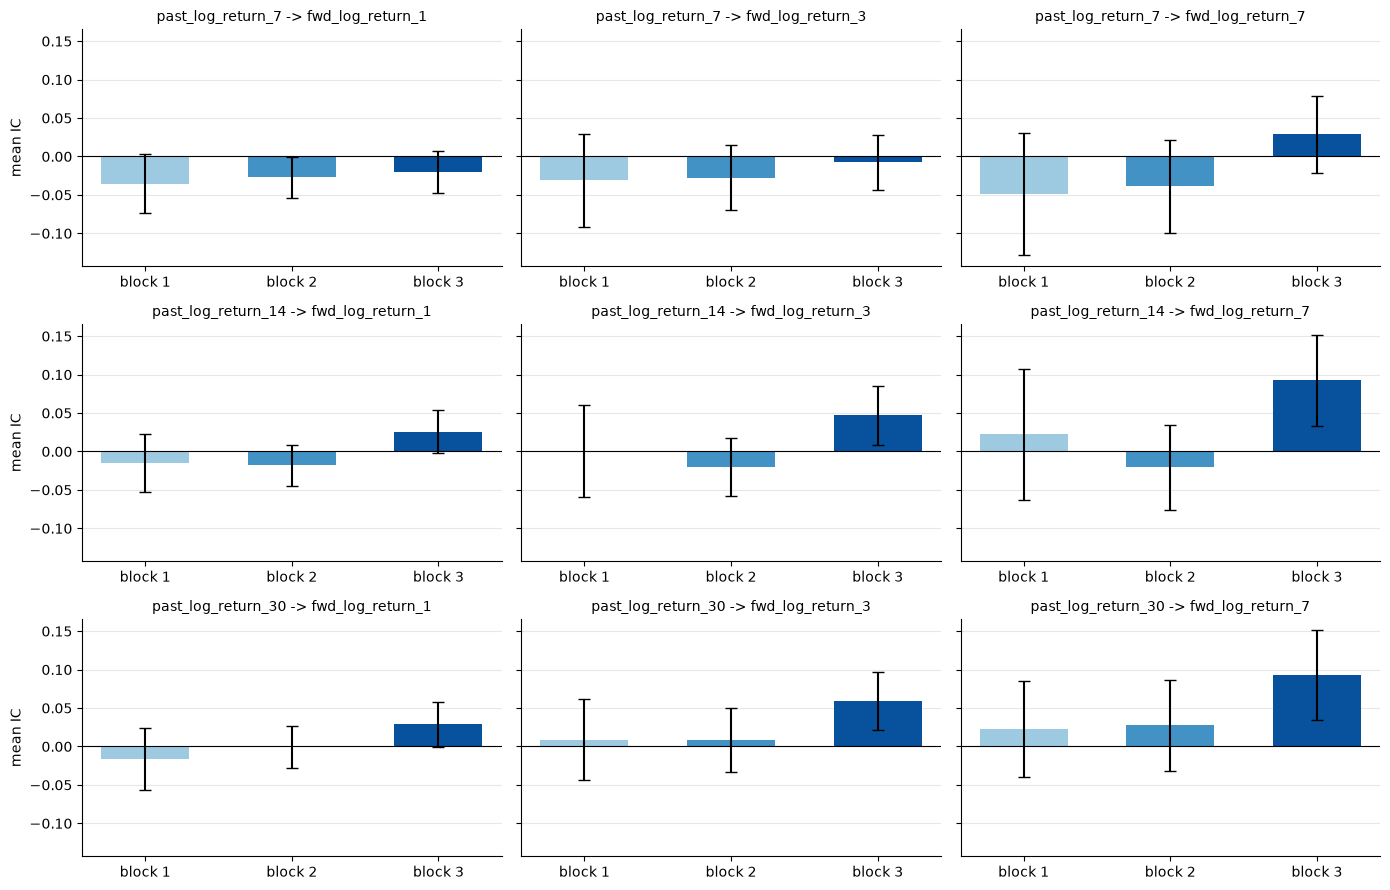

In [14]:
# one chart per feature (row) and label (column), all on the same y-axis so the sizes can be compared
fig, axes = plt.subplots(len(features), len(labels), figsize=(14, 9), sharey=True)

# the summary as a plain table, so we can pick the rows of one pair
table = fold_summary.reset_index()

# one shade of blue per block, from light (oldest) to dark (newest)
colors = ["#9ecae1", "#4292c6", "#08519c"]

for i, feature in enumerate(features):
    for j, label in enumerate(labels):
        # the chart for this pair and its three blocks
        ax = axes[i, j]
        pair = table[(table["feature"] == feature) & (table["label"] == label)].set_index("fold")
        # the distance from the mean IC to each end of its confidence interval
        error = [pair["mean_ic"] - pair["ci_low"], pair["ci_high"] - pair["mean_ic"]]
        # one bar per block: the mean IC, with its confidence interval
        ax.bar(pair.index, pair["mean_ic"], yerr=error, capsize=4, width=0.6, color=colors)
        # a line at 0 so positive and negative are easy to see
        ax.axhline(0, color="black", linewidth=0.8)
        # title: which feature and which label
        ax.set_title(f"{feature} -> {label}", fontsize=10)
        # light horizontal grid behind the bars, no box on the top and right
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        # axis name only on the left charts
        if j == 0:
            ax.set_ylabel("mean IC")

plt.tight_layout()
plt.show()

### Mean target per feature quintile by block

The same quintile calculation as above, run inside each block (rows purged for the label's horizon).

In [15]:
# the mean target of every quintile, averaged over days, in percent: one row per block, feature and label
fold_quantile_means = pd.concat({
    fold: pd.DataFrame({
        (feature, label): daily_quantile_means(fold_rows(df, start, end, n), feature, label).mean() * 100
        for feature in features
        for label, n in labels.items()
    }).T
    for fold, (start, end) in folds.items()
})

fold_quantile_means.round(3)

quantile                                         1      2      3      4      5
block 1 past_log_return_7  fwd_log_return_1  0.123  0.134  0.160  0.123  0.536
                           fwd_log_return_3  0.256  0.542  0.501  0.505  1.173
                           fwd_log_return_7  0.799  1.285  0.826  1.078  1.702
        past_log_return_14 fwd_log_return_1  0.071  0.137  0.216  0.245  0.461
                           fwd_log_return_3  0.211  0.217  0.717  0.738  1.131
                           fwd_log_return_7  0.033  0.837  1.171  1.902  1.868
        past_log_return_30 fwd_log_return_1  0.067  0.197  0.174  0.429  0.255
                           fwd_log_return_3  0.210  0.613  0.602  0.944  0.685
                           fwd_log_return_7  0.812  1.263  1.136  1.054  1.538
block 2 past_log_return_7  fwd_log_return_1 -0.139 -0.264 -0.167 -0.160 -0.162
                           fwd_log_return_3 -0.438 -0.607 -0.391 -0.598 -0.547
                           fwd_log_return_7 -0.686 -1.206 -0.800 -1.082 -1.465
        past_log_return_14 fwd_log_return_1 -0.142 -0.217 -0.185 -0.181 -0.167
                           fwd_log_return_3 -0.376 -0.522 -0.549 -0.573 -0.563
                           fwd_log_return_7 -0.737 -0.977 -1.208 -1.119 -1.198
        past_log_return_30 fwd_log_return_1 -0.234 -0.188 -0.111 -0.299 -0.067
                           fwd_log_return_3 -0.555 -0.663 -0.435 -0.664 -0.295
                           fwd_log_return_7 -1.222 -1.145 -0.913 -1.334 -0.642
block 3 past_log_return_7  fwd_log_return_1 -0.379 -0.230 -0.253 -0.363 -0.305
                           fwd_log_return_3 -1.188 -0.572 -0.777 -1.011 -0.899
                           fwd_log_return_7 -3.052 -1.222 -1.444 -1.746 -2.008
        past_log_return_14 fwd_log_return_1 -0.584 -0.361 -0.294 -0.245 -0.039
                           fwd_log_return_3 -1.536 -1.186 -0.757 -0.599 -0.354
                           fwd_log_return_7 -3.729 -2.218 -1.587 -1.095 -0.834
        past_log_return_30 fwd_log_return_1 -0.681 -0.201 -0.342 -0.134 -0.161
                           fwd_log_return_3 -1.930 -0.711 -0.730 -0.572 -0.475
                           fwd_log_return_7 -4.288 -1.200 -1.568 -1.202 -1.184

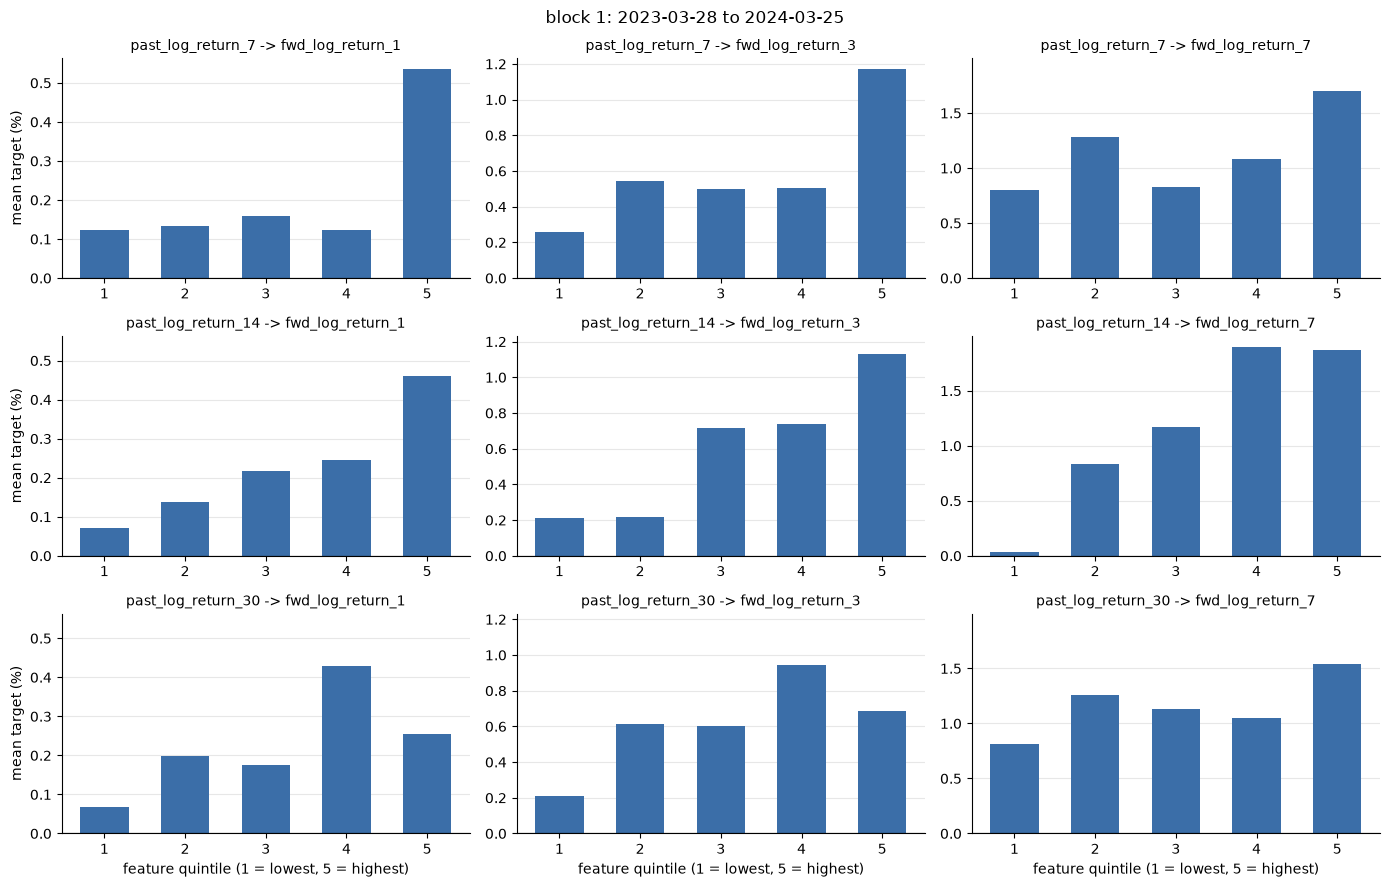

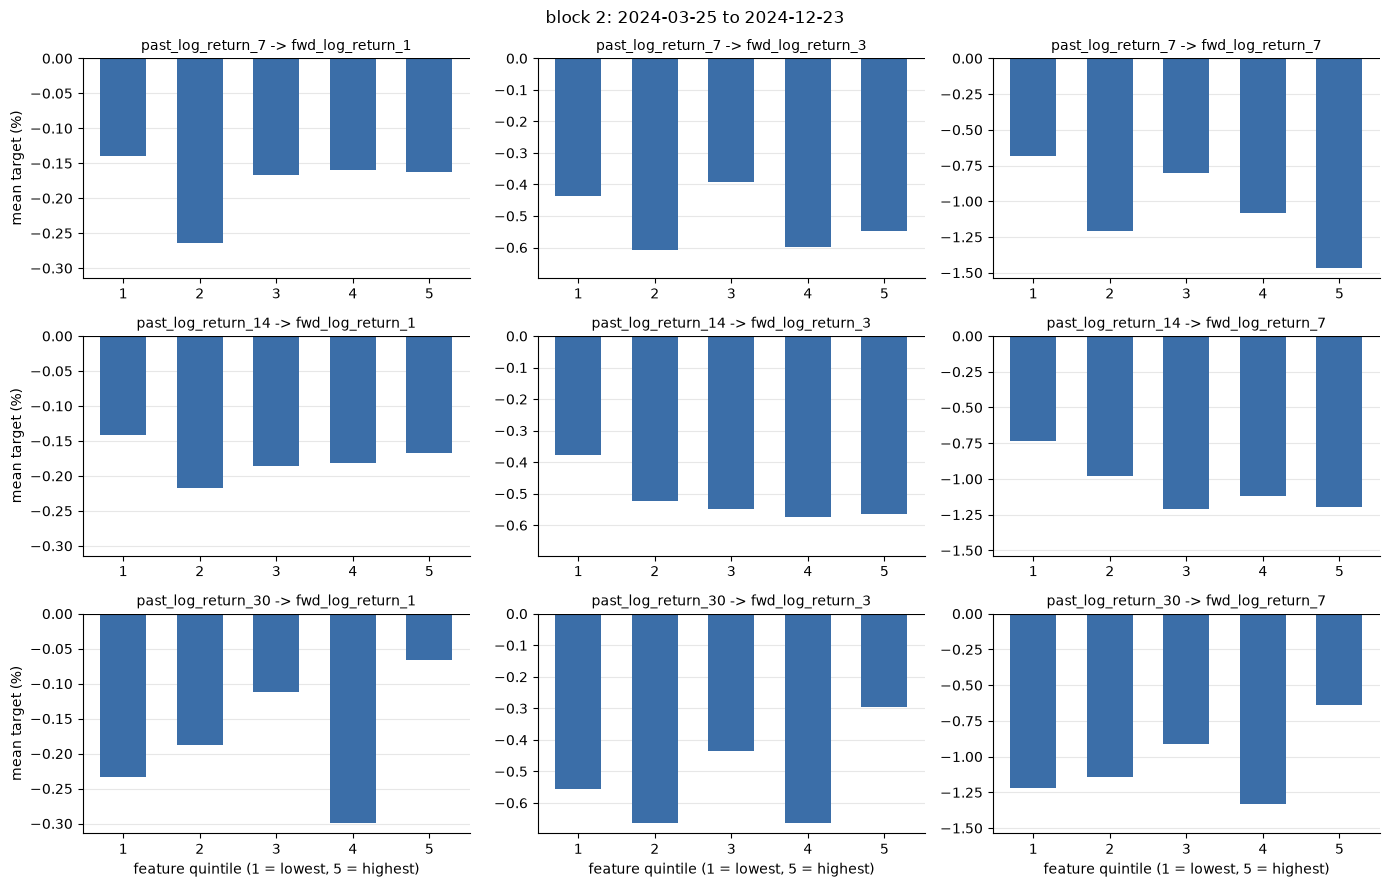

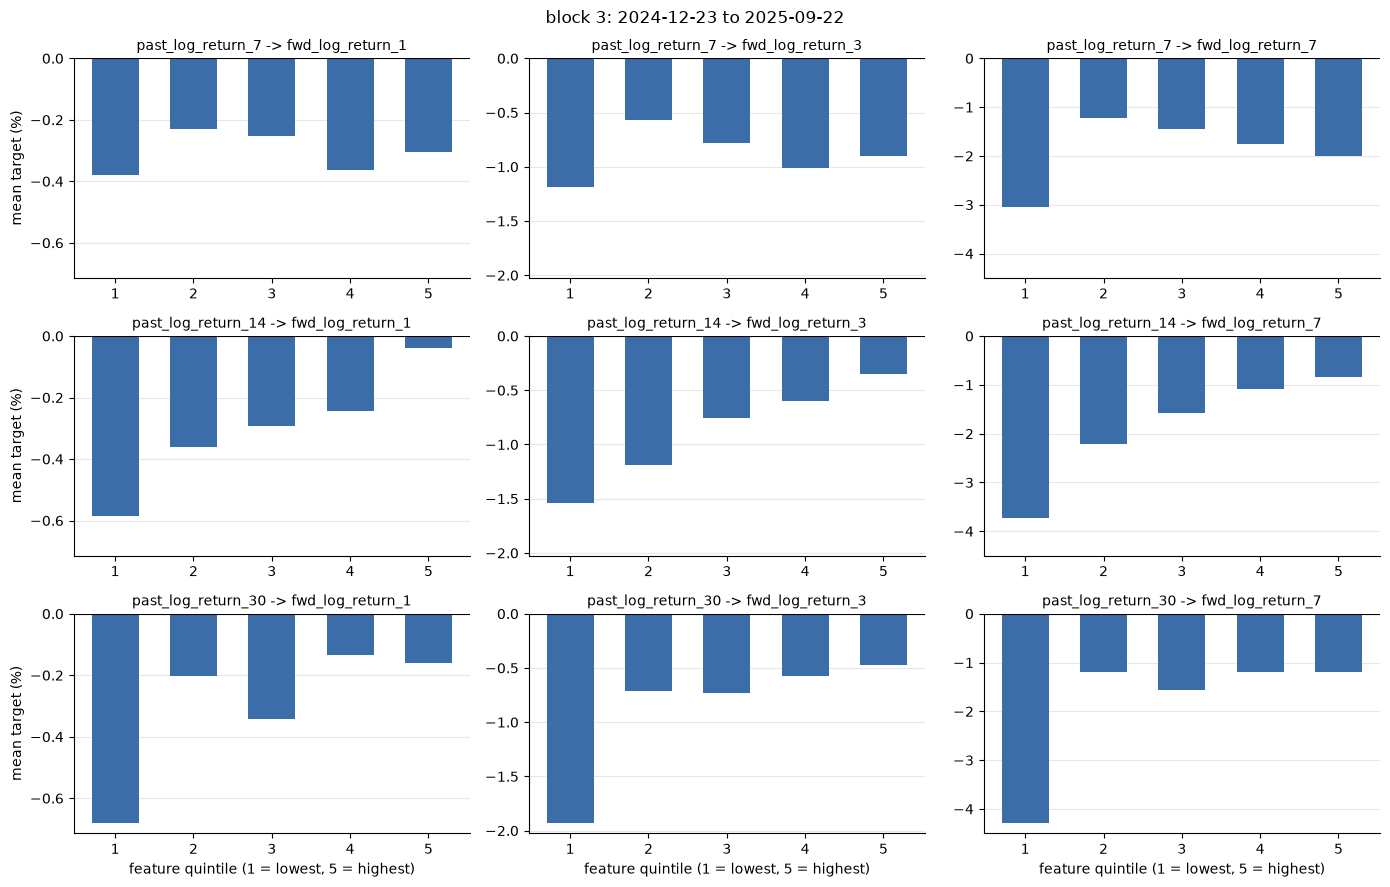

In [16]:
# one chart like the quintile chart above for each block
for fold, (start, end) in folds.items():
    fig, axes = plt.subplots(len(features), len(labels), figsize=(14, 9), sharey="col")
    # a title for the whole figure with the block and its dates
    fig.suptitle(f"{fold}: {start.date()} to {end.date()}", fontsize=12)

    for i, feature in enumerate(features):
        for j, label in enumerate(labels):
            # the chart for this pair
            ax = axes[i, j]
            # the mean target in percent of the five quintiles of this pair in this block
            means = fold_quantile_means.loc[(fold, feature, label)]
            # one bar per quintile
            ax.bar(means.index, means, width=0.6, color="#3b6ea8")
            # a line at 0 so up and down are easy to see
            ax.axhline(0, color="black", linewidth=0.8)
            # title: which feature and which label
            ax.set_title(f"{feature} -> {label}", fontsize=10)
            # the quintile numbers on the x-axis
            ax.set_xticks(list(means.index))
            # light horizontal grid behind the bars, no box on the top and right
            ax.grid(axis="y", alpha=0.3)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
            # axis names only on the outer charts
            if i == len(features) - 1:
                ax.set_xlabel("feature quintile (1 = lowest, 5 = highest)")
            if j == 0:
                ax.set_ylabel("mean target (%)")

    plt.tight_layout()
    plt.show()